# Notebook de obtención, limpieza y transformación de datos — Fase 2

**Proyecto:** Caracterización de alojamientos Airbnb en Santiago de chile 

---

### ¿Qué es un *pipeline* de preprocesamiento?

Un *pipeline* es una secuencia ordenada de pasos por los que pasan los datos crudos hasta
quedar listos para analizar o modelar. En este notebook el flujo es:

**Obtener → Explorar → Limpiar → Transformar → Escalar → Validar**

Cada paso se implementa como una **función** reutilizable. Trabajar con funciones (en vez
de copiar y pegar código) hace el proceso más ordenado, más fácil de corregir y permite
reutilizar la misma lógica sobre cualquier columna sin reescribirla.

## Introducción

Las plataformas de alojamiento temporal, como Airbnb, ofrecen
distintas alternativas de hospedaje en Santiago de Chile, con
características que varían según su ubicación, tipo de alojamiento,
capacidad, precio publicado y disponibilidad.

Conocer como se caracteriza este mercado permitirá que los usuarios puedan
incorporarse como anfitriones entendiendo cómo funciona la oferta existente.

El proyecto utilizará datos públicos de Inside Airbnb para
realizar una caracterización descriptiva de los alojamientos
publicados en Santiago de Chile.

**Objetivo general Fase 2.** Construir un *pipeline* reproducible que deje el *dataset*
limpio, codificado y escalado, listo para el modelado posterior.

**Objetivos específicos.**
- Obtener y explorar los datos verificando su estructura y calidad.
- Limpiar gestionando rigurosamente los valores nulos.
- Transformar las variables categóricas nominales con codificación One-Hot.
- Estandarizar las variables continuas.
- Validar técnicamente el resultado.

**Atributos:** **Atributos del estudio:** `neighbourhood_cleansed`, `room_type`, `host_is_superhost`,
`price`, `accommodates`, `latitude`, `estimated_occupancy_l365d`, `reviews_per_month`,
`bedrooms`, `beds`, `minimum_nights` y `maximum_nights`. El estudio es descriptivo,
por lo que no se declara una variable objetivo en esta fase.

### Librerías utilizadas

| Librería | Para qué la usamos |
|---|---|
| `numpy` | Cálculo numérico y manejo de arreglos. |
| `pandas` | Cargar y manipular la tabla de datos (el `DataFrame`). |
| `matplotlib` | Generar los gráficos (*boxplots*). |
| `sklearn.preprocessing` | Las herramientas de codificación (`LabelEncoder`, `OneHotEncoder`) y escalamiento (`RobustScaler`). |

`np.random.seed(42)` fija la semilla aleatoria: garantiza que cualquier proceso con azar
dé **siempre el mismo resultado**, lo que asegura la *reproducibilidad* exigida en la fase.

In [1]:
import sys                                   # intérprete del kernel
import subprocess                            # instalar paquetes faltantes
import importlib                             # refrescar el sistema de importación
import importlib.util                        # comprobar si un paquete está instalado
import re                                    #expresiones regulares para limpiar textos

# Verificación del entorno: instala en el intérprete del kernel lo que falte.
REQUERIDOS = {                               # módulo: nombre del paquete en pip
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",               # se importa como sklearn, se instala como scikit-learn
}
faltantes = [pkg for mod, pkg in REQUERIDOS.items()
             if importlib.util.find_spec(mod) is None]

if faltantes:
    print("Instalando:", ", ".join(faltantes))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *faltantes])
    importlib.invalidate_caches()

import numpy as np                           # cálculo numérico y operaciones vectorizadas
import pandas as pd                          # estructuras tabulares: Series y DataFrame
import matplotlib.pyplot as plt              # gráficos de control
from sklearn import preprocessing            # LabelEncoder y OneHotEncoder
from sklearn.preprocessing import StandardScaler   # estandarización z-score

# Reproducibilidad: fijamos la semilla aleatoria del entorno
np.random.seed(42)

%matplotlib inline

## Configuración del entorno y de las rutas

Antes de cargar nada conviene comprobar el entorno y dejar declaradas las rutas.
Se usan rutas **relativas** a la raíz del repositorio, coherentes con la
estructura creada en la Fase 1: una ruta absoluta como `C:/Users/...` funciona en
un solo computador del mundo.

In [2]:
from pathlib import Path      # manejo de rutas independiente del sistema operativo
import sys

# sys.version trae la versión completa con fecha de compilación;
# split()[0] deja solo el número, que es lo único que hay que comprobar.
print("Python:", sys.version.split()[0])
for lib, mod in [("numpy", np), ("pandas", pd)]:
    print(f"{lib:8}:", mod.__version__)

# Estructura del proyecto. parents=True crea las carpetas intermedias;
# exist_ok=True evita el error si ya existen.
def localizar_raiz(inicio=None):
    """
    Devuelve la raíz del proyecto.

    Jupyter abre el kernel en la carpeta donde está guardado el cuaderno, no en la
    carpeta desde la que se lanzó JupyterLab. Como cada cuaderno vive en la carpeta
    de su fase (F1, F2, F3 o F4), si la carpeta de trabajo es una de ellas la raíz
    es la carpeta superior. Si el cuaderno se ejecuta desde la raíz, se usa tal cual.
    """
    inicio = Path.cwd() if inicio is None else Path(inicio)
    return inicio.parent if inicio.name in {"F1", "F2", "F3", "F4"} else inicio


RAIZ = localizar_raiz()                 # la misma función del cuaderno de la Fase 1
DIR_CRUDO = RAIZ / "data" / "raw"            # datos originales: nunca se modifican
DIR_PROCESADO = RAIZ / "data" / "processed"  # resultado del pipeline
DIR_DOCS = RAIZ / "docs"                     # diccionario, bitácora y metadatos
for carpeta in (DIR_CRUDO, DIR_PROCESADO, DIR_DOCS):
    carpeta.mkdir(parents=True, exist_ok=True)

ARCHIVO = DIR_CRUDO / "datasetairbnb.csv"
print("\nArchivo esperado en:", ARCHIVO)

Python: 3.14.8
numpy   : 2.5.4
pandas  : 3.1.1

Archivo esperado en: c:\Users\goku9\Desktop\grupo_8_magister_mcdi500\data\raw\datasetairbnb.csv


### Procedencia del conjunto de datos:

| Campo | Valor |
| --- | --- |
| Título | Inside Airbnb — Santiago, Región Metropolitana ("datasetairbnb.csv") |
| Autor | Inside Airbnb (Murray Cox) |
| Plataforma | Inside Airbnb |
| Enlace | `http://insideairbnb.com/get-the-data/` |
| Estructura esperada | 18904 filas × 90 columnas |
| Unidad de observación | Un alojamiento publicado en Airbnb en Santiago de Chile |

**Referencia en APA 7 para el informe:**

> Inside Airbnb. (2026). *Santiago, Región Metropolitana, Chile — Listings Data* [Conjunto de datos]. Inside Airbnb. http://insideairbnb.com/get-the-data/

Documentar la procedencia no es un trámite: sin ella, nadie puede verificar sobre
qué versión del archivo se trabajó.

## 1. Obtención de los datos

**Qué hace este paso.** Lee el archivo CSV y lo carga en un `DataFrame` (la tabla con la
que trabajaremos).

**Por qué con una función.** Encapsulamos la lectura en `cargar_datos(ruta)` con un bloque
`try / except`. Así, si el archivo no existe, en lugar de un error técnico confuso, el
usuario recibe un mensaje claro indicando qué revisar. La función, además, imprime las
dimensiones cargadas, lo que sirve como primera verificación de que el archivo se leyó bien.

Es una función (def) que recibe un parámetro, ruta (el nombre del archivo), y se encarga de leer el CSV. El texto entre """...""" es el docstring: solo documentación, no se ejecuta. El bloque try/except maneja errores: intenta leer el archivo con pd.read_csv(ruta) y, si no lo encuentra, en vez de romperse muestra un mensaje claro de qué revisar (usando un f-string, que inserta el valor de ruta en el texto). Luego print informa el tamaño con df.shape[0] (filas) y df.shape[1] (columnas) —de ahí el "18904 filas y 90 columnas"— y return df entrega la tabla para usarla después. Al final, df_crudo = cargar_datos(ARCHIVO) llama a la función y guarda el original; df es la copia sobre la que se trabaja.

In [3]:
def cargar_datos(ruta):
    """
    Carga un conjunto de datos desde un archivo CSV.

    Parámetros
    ----------
    ruta : str o Path
        Ruta del archivo CSV.

    Retorna
    -------
    pd.DataFrame
        Datos cargados en un DataFrame.

    Lanza
    -----
    FileNotFoundError
        Si el archivo no existe, con un mensaje que indica dónde debe estar.
    """
    ruta = Path(ruta)
    try:
        # En este archivo los faltantes de bmi vienen como el texto 'N/A':
        # na_values los convierte en NaN al leer.
        df = pd.read_csv(ruta, na_values=["N/A"])
    except FileNotFoundError:
        # from None oculta la traza interna de pandas: queda solo el mensaje útil.
        raise FileNotFoundError(
            f"No se encontró {ruta.name} en {ruta.parent.resolve()}.\n"
            "Descárguelo desde el enlace de la tabla de procedencia y guárdelo en "
            "data/raw/ de la raíz del proyecto."
        ) from None
    print(f"Datos cargados: {df.shape[0]} filas y {df.shape[1]} columnas.")
    return df


df_crudo = cargar_datos(ARCHIVO)

# Se conserva el original sin modificaciones y se trabaja sobre una copia
df = df_crudo.copy()
df.head()


Datos cargados: 18904 filas y 90 columnas.


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,49392,https://www.airbnb.com/rooms/49392,20260923225049,2026-09-26,NaN,Share my Flat in Providencia,<b>The space</b><br />Departamento en el barri...,NaN,https://a0.muscache.com/pictures/3740612/b1850...,224592,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
1,52811,https://www.airbnb.com/rooms/52811,20260923225049,2026-09-26,NaN,Suite Providencia 1 Santiago Chile,Apartment located on the subway station Manuel...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,244792,...,4.59,4.64,4.36,NaN,NaN,3,3,0,0,0.23
2,80482,https://www.airbnb.com/rooms/80482,20260923225049,2026-09-25,NaN,Room Private for Woman,"Near transport, subway, malls supermarkets, wa...",NaN,https://a0.muscache.com/pictures/3633153/dffd5...,154527,...,NaN,NaN,NaN,NaN,NaN,2,0,2,0,NaN
3,88944,https://www.airbnb.com/rooms/88944,20260923225049,2026-09-26,NaN,COZY APT. PROVIDENCIA METRO WIFI TV,Spacious and cozy apartment. It has excellent ...,NaN,https://a0.muscache.com/pictures/8fd1c60d-5a8f...,485358,...,4.89,4.96,4.73,NaN,NaN,1,1,0,0,1.37
4,90694,https://www.airbnb.com/rooms/90694,20260923225049,2026-09-26,NaN,Apartment x Rent in Providencia 802,APARTMENT<br />Furnished Apartments with one b...,NaN,https://a0.muscache.com/pictures/d29b8d52-ca46...,491253,...,4.83,4.77,4.43,NaN,NaN,2,2,0,0,0.41


Mostramos las primeras filas para confirmar visualmente que las columnas se cargaron correctamente:

`head()` muestra las primeras cinco filas. Es la comprobación más barata que existe: confirma que el separador se interpretó bien, que los nombres de columna son los esperados y que los valores no quedaron corridos de columna.

> > **Qué mirar aquí.** Que las columnas numéricas aparezcan como números. En este archivo
> `price` viene como texto (`$55,106.00`), con símbolo y separadores de miles: así cargada,
> cualquier operación numérica falla. Se corrige en la sección 2, antes de medir atípicos.

In [4]:
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,49392,https://www.airbnb.com/rooms/49392,20260923225049,2026-09-26,NaN,Share my Flat in Providencia,<b>The space</b><br />Departamento en el barri...,NaN,https://a0.muscache.com/pictures/3740612/b1850...,224592,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
1,52811,https://www.airbnb.com/rooms/52811,20260923225049,2026-09-26,NaN,Suite Providencia 1 Santiago Chile,Apartment located on the subway station Manuel...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,244792,...,4.59,4.64,4.36,NaN,NaN,3,3,0,0,0.23
2,80482,https://www.airbnb.com/rooms/80482,20260923225049,2026-09-25,NaN,Room Private for Woman,"Near transport, subway, malls supermarkets, wa...",NaN,https://a0.muscache.com/pictures/3633153/dffd5...,154527,...,NaN,NaN,NaN,NaN,NaN,2,0,2,0,NaN
3,88944,https://www.airbnb.com/rooms/88944,20260923225049,2026-09-26,NaN,COZY APT. PROVIDENCIA METRO WIFI TV,Spacious and cozy apartment. It has excellent ...,NaN,https://a0.muscache.com/pictures/8fd1c60d-5a8f...,485358,...,4.89,4.96,4.73,NaN,NaN,1,1,0,0,1.37
4,90694,https://www.airbnb.com/rooms/90694,20260923225049,2026-09-26,NaN,Apartment x Rent in Providencia 802,APARTMENT<br />Furnished Apartments with one b...,NaN,https://a0.muscache.com/pictures/d29b8d52-ca46...,491253,...,4.83,4.77,4.43,NaN,NaN,2,2,0,0,0.41


## 2. Exploración inicial

**Qué hace este paso.** Antes de modificar nada, miramos el estado original de los datos.
Esto nos da la "línea base" contra la cual verificaremos después cada transformación.

La función `explorar_dataframe` reporta cuatro cosas:
1. **Dimensiones** (`shape`): cuántas filas y columnas hay.
2. **Tipos de datos** (`dtypes`): qué columnas son numéricas y cuáles son texto. Las de
   texto (`object`) son las que tendremos que codificar más adelante.
3. **Valores nulos** (`isnull().sum()`): cuántos datos faltan en cada columna. Aquí
   detectaremos que variables como `bedrooms`, `beds`, `reviews_per_month` y `price` tienen huecos.
4. **Estadísticos descriptivos** (`describe()`): media, mínimo, máximo, etc., de las
   variables numéricas, útil para detectar rangos raros o valores atípicos (como errores de digitación en tarifas).

In [5]:
def explorar_dataframe(df):
    """Resumen exploratorio: dimensiones, tipos, nulos y estadisticos descriptivos."""
    print("Dimensiones:", df.shape)
    print("\nTipos de datos:")
    print(df.dtypes)
    print("\nValores nulos por columna:")
    print(df.isnull().sum())
    print("\nEstadisticos descriptivos (variables numericas):")
    return df.describe()


explorar_dataframe(df)

Dimensiones: (18904, 90)

Tipos de datos:
id                                                int64
listing_url                                         str
scrape_id                                         int64
last_scraped                                        str
source                                              str
                                                 ...   
calculated_host_listings_count                    int64
calculated_host_listings_count_entire_homes       int64
calculated_host_listings_count_private_rooms      int64
calculated_host_listings_count_shared_rooms       int64
reviews_per_month                               float64
Length: 90, dtype: object

Valores nulos por columna:
id                                                  0
listing_url                                         0
scrape_id                                           0
last_scraped                                        0
source                                          18041
                  

,id,scrape_id,neighborhood_overview,host_id,host_profile_id,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,1.890400e+04,1.890400e+04,0.0,1.890400e+04,1.890400e+04,0.0,18904.000000,18904.000000,18904.000000,18904.000000,...,16035.000000,16035.000000,16034.000000,16035.000000,0.0,18904.000000,18904.000000,18904.000000,18904.000000,16035.000000
mean,1.138817e+18,2.026092e+13,NaN,4.103115e+16,1.494208e+18,NaN,6.145736,5.588606,3.956835,5.335908,...,4.863526,4.850086,4.832075,4.759926,NaN,11.913246,11.176788,0.694086,0.015552,2.091876
std,5.904423e+17,3.906353e-03,NaN,2.619132e+17,6.823452e+16,NaN,3.857891,3.377418,3.638660,3.381593,...,0.310268,0.332669,0.308647,0.376591,NaN,29.286912,29.353545,2.483804,0.203059,2.142181
min,4.939200e+04,2.026092e+13,NaN,1.961100e+04,1.462507e+18,NaN,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,NaN,1.000000,0.000000,0.000000,0.000000,0.010000
25%,8.702468e+17,2.026092e+13,NaN,1.062628e+08,1.465497e+18,NaN,3.000000,3.000000,1.000000,2.000000,...,4.850000,4.830000,4.790000,4.700000,NaN,1.000000,1.000000,0.000000,0.000000,0.550000
50%,1.349967e+18,2.026092e+13,NaN,2.871964e+08,1.469255e+18,NaN,7.000000,6.000000,3.000000,5.000000,...,4.940000,4.940000,4.920000,4.850000,NaN,2.000000,2.000000,0.000000,0.000000,1.510000
75%,1.603997e+18,2.026092e+13,NaN,5.329788e+08,1.470614e+18,NaN,9.000000,8.000000,7.000000,8.000000,...,5.000000,5.000000,5.000000,4.960000,NaN,9.000000,7.000000,0.000000,0.000000,2.950000
max,1.780801e+18,2.026092e+13,NaN,1.780509e+18,1.780748e+18,NaN,17.000000,11.000000,15.000000,11.000000,...,5.000000,5.000000,5.000000,5.000000,NaN,220.000000,220.000000,28.000000,4.000000,49.820000


También revisamos **cuántas categorías distintas** tiene cada variable de texto y cuántas
veces aparece cada una. Esto cumple dos funciones: detectar errores de tipeo o categorías
inesperadas, y conocer el orden en que aparecerán las categorías al codificarlas.

In [6]:
# Conteo de categorias en las variables nominales (control de calidad de entrada)
columnas_categoricas = ['room_type', 'neighbourhood_cleansed']
for col in columnas_categoricas:
    print(f"\n{col}:")
    # dropna=False incluye los nulos como una categoría más: si una variable
    # tiene faltantes queremos verlos aquí, no que desaparezcan del conteo.
    print(df[col].value_counts(dropna=False))


room_type:
room_type
Entire home/apt    15383
Private room        3414
Hotel room            56
Shared room           51
Name: count, dtype: int64

neighbourhood_cleansed:
neighbourhood_cleansed
Santiago               7354
Providencia            3021
Las Condes             2819
Ñuñoa                  1922
Lo Barnechea            876
Estación Central        445
La Florida              413
Vitacura                348
Recoleta                274
Macul                   231
San Miguel              183
Independencia           151
La Reina                138
Maipú                   106
La Cisterna              95
Peñalolén                93
Pudahuel                 92
San Joaquín              86
Huechuraba               56
Quinta Normal            55
Renca                    33
Quilicura                32
Cerrillos                19
Lo Prado                 16
Conchalí                 12
La Granja                 9
Pedro Aguirre Cerda       8
El Bosque                 8
Cerro Navia         

### El diccionario de variables

Antes de limpiar hay que declarar **qué es cada variable**. Esta es la decisión
que determina todo el preprocesamiento posterior.

La idea central: **el tipo de dato no dice qué es una variable**. En este conjunto
`id`, `latitude` y `accommodates` son todas numéricas, y sin embargo exigen
tratamientos completamente distintos.

| Rol analítico | Qué preprocesamiento exige |
| --- | --- |
| **Continua** | Detección de atípicos, imputación, escalamiento |
| **Binaria** | Codificación 0/1 y revisión de desbalance |
| **Nominal** | *One-hot encoding* |
| **Ordinal** | Codificación con el orden declarado explícitamente |
| **Identificador** | Verificar unicidad y excluir del análisis |
| **Objetivo** | Se preserva sin transformar en esta fase |

Como tenemos el diccionario en ***csv***, se toma la decición de cargarlo a través de código.

In [7]:
# El diccionario oficial del grupo se LEE desde docs/: no se reescribe aquí,
# para no sobrescribir el entregable con una versión parcial.
diccionario = pd.read_csv(DIR_DOCS / "diccionario_variables.csv")

# Control de calidad: el diccionario debe describir exactamente las columnas del archivo
faltan = set(df_crudo.columns) - set(diccionario["variable"])
sobran = set(diccionario["variable"]) - set(df_crudo.columns)
assert not faltan and not sobran, f"Diccionario desalineado. Faltan: {faltan} | Sobran: {sobran}"
print(f"Diccionario cargado: {len(diccionario)} variables, alineado con el archivo crudo.\n")

print("Variables por rol analítico:")
print(diccionario["rol_analitico"].value_counts())

# Variables que usa este estudio y lo que dice el diccionario de cada una
variables_estudio = [
    "neighbourhood_cleansed", "room_type", "host_is_superhost",
    "price", "accommodates", "latitude",
    "estimated_occupancy_l365d", "reviews_per_month",
    "bedrooms", "beds", "minimum_nights", "maximum_nights",
]
diccionario.loc[diccionario["variable"].isin(variables_estudio),
                ["variable", "rol_analitico", "porcentaje_nulos", "valores_unicos", "descripcion"]]

Diccionario cargado: 90 variables, alineado con el archivo crudo.

Variables por rol analítico:
rol_analitico
discreta             29
continua             19
identificador        10
nominal              10
fecha                 8
texto libre           6
binaria               5
alta cardinalidad     2
ordinal               1
Name: count, dtype: int64


,variable,rol_analitico,porcentaje_nulos,valores_unicos,descripcion
24,host_is_superhost,binaria,0.00,2,Indica si el anfitrión tiene categoría Superho...
34,neighbourhood_cleansed,nominal,0.00,32,Nombre del sector territorial obtenido por geo...
36,latitude,continua,0.00,12384,Latitud geográfica del alojamiento.
39,room_type,nominal,0.00,4,"Modalidad de alojamiento (entero, habitación p..."
40,accommodates,discreta,0.00,16,Cantidad máxima de huéspedes que puede alojar ...
43,bedrooms,discreta,0.03,21,Número de dormitorios del alojamiento.
44,beds,discreta,1.07,25,Número de camas ofrecidas.
46,price,continua,4.75,10084,"Precio diario publicado del alojamiento, según..."
52,minimum_nights,discreta,0.03,55,Número mínimo de noches exigido para reservar.
53,maximum_nights,discreta,0.03,128,Número máximo de noches permitido para reservar.


### Variables descartadas del diccionario

Del diccionario de 90 variables se descartan 17 por no aportar información:

- **14 columnas 100% vacías** (por ejemplo `host_response_time`, `bathrooms`, `neighbourhood_group_cleansed`): no contienen ningún dato.
- **3 columnas con un único valor** (`scrape_id`, `source`, `has_availability`): valen lo mismo en todas las filas, por lo que no permiten diferenciar alojamientos.

Ninguna de las 12 variables del estudio está entre ellas.

In [8]:
# Columnas 100% vacías y columnas con un único valor: no aportan información
vacias = df_crudo.columns[df_crudo.isna().all()].tolist()
constantes = [c for c in df_crudo.columns
              if c not in vacias and df_crudo[c].nunique(dropna=True) == 1]

print(f"Columnas 100% vacías ({len(vacias)}):")
print(vacias)
print(f"\nColumnas con un único valor ({len(constantes)}):")
print(constantes)


Columnas 100% vacías (14):
['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'instant_bookable']

Columnas con un único valor (3):
['scrape_id', 'source', 'has_availability']


In [9]:
for c in vacias:
    print(c)

neighborhood_overview
host_since
host_response_time
host_response_rate
host_acceptance_rate
host_thumbnail_url
host_neighbourhood
host_total_listings_count
host_verifications
neighbourhood
neighbourhood_group_cleansed
bathrooms
calendar_updated
instant_bookable


### Valores atípicos: medir antes de decidir

La sección siguiente imputa con la mediana «porque hay valores extremos». Esa
afirmación hay que **demostrarla**, no enunciarla. Se usa el criterio del rango
intercuartílico:

$$\text{atípico si} \quad x < Q_1 - 1{,}5 \cdot \text{RIC} \quad \text{o} \quad x > Q_3 + 1{,}5 \cdot \text{RIC}$$

In [10]:
#Me dió error al detectar los atípicos, por lo que transformé la variable "price" a crudo, eliminando $
# 1. Convertimos 'price' a float directamente (sin el 'if dtype == object' que se lo saltaba)
df_crudo["price"] = pd.to_numeric(
    df_crudo["price"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False).str.strip(),
    errors="coerce"
)
df["price"] = df_crudo["price"].copy()
        
def detectar_atipicos_iqr(serie, factor=1.5):
    """Identifica valores atípicos por el criterio del rango intercuartílico.

    Retorna
    -------
    tuple(np.ndarray, float, float)
        Máscara booleana de atípicos, límite inferior y límite superior.
    """
    # dropna() es obligatorio: un NaN propagaría y devolvería NaN como cuartil
    valores = serie.dropna().to_numpy(dtype="float64")

    # np.percentile con una lista devuelve varios percentiles de una vez
    q1, q3 = np.percentile(valores, [25, 75])
    ric = q3 - q1                                  # rango intercuartílico
    limite_inf, limite_sup = q1 - factor * ric, q3 + factor * ric

    # El operador | es el "o" elemento a elemento de pandas. Con 'or' fallaría:
    # 'or' espera un único booleano, no una serie completa.
    mascara = (serie < limite_inf) | (serie > limite_sup)
    # Comparar con NaN da False pero deja NA: fillna(False) lo hace explícito
    return mascara.fillna(False).to_numpy(), limite_inf, limite_sup


filas = []
columnas_a_evaluar = ["price", "accommodates", "latitude", "estimated_occupancy_l365d", "reviews_per_month", "bedrooms", "beds", "minimum_nights", "maximum_nights"]
for col in columnas_a_evaluar:
    mascara, inf, sup = detectar_atipicos_iqr(df[col])
    filas.append({
        "variable": col,
        "limite_inf": round(inf, 2),
        "limite_sup": round(sup, 2),
        "n_atipicos": int(mascara.sum()),          # sobre booleanos, sum() cuenta True
        "pct_atipicos": round(mascara.mean() * 100, 2),
        "media": round(df[col].mean(), 2),
        "mediana": round(df[col].median(), 2),
    })
pd.DataFrame(filas)

,variable,limite_inf,limite_sup,n_atipicos,pct_atipicos,media,mediana
0,price,-22340.75,143901.25,1596,8.44,108445.69,55106.00
1,accommodates,-1.00,7.00,573,3.03,3.12,3.00
2,latitude,-33.50,-33.38,1795,9.50,-33.44,-33.44
3,estimated_occupancy_l365d,-189.00,315.00,0,0.00,76.19,42.00
4,reviews_per_month,-3.05,6.55,664,3.51,2.09,1.51
5,bedrooms,-0.50,3.50,499,2.64,1.40,1.00
6,beds,-2.00,6.00,482,2.55,2.12,2.00
7,minimum_nights,-0.50,3.50,1701,9.00,3.34,2.00
8,maximum_nights,-775.00,2265.00,2,0.01,227841.50,365.00


> **Cómo se lee esta tabla.** Donde la **media se aleja de la mediana** hay
> asimetría: la media queda arrastrada por los valores extremos. Ese es el
> argumento técnico —no una preferencia— para imputar con la mediana. Escríbanlo
> así en el informe, con las cifras de su propio conjunto.

## 3. Limpieza de datos

Limpiar significa dejar los datos completos y consistentes. Tomamos tres decisiones, cada
una justificada técnicamente:

**a) Eliminar `id` y acotar a las variables del estudio.** `id` es un identificador único por
anuncio (se verifica antes de descartarlo) y el archivo bruto incluye metadatos de *scraping*
(URLs, textos libres en HTML y campos vacíos) que no aportan al análisis de tarifas ni ocupación.
Se conservan solo las variables analíticas del estudio.

**b) Acotar `maximum_nights` a 1125.** El archivo contiene valores imposibles (hasta
2.147.483.647 noches), detectados durante la validación de la sección 6. Se acotan al tope
habitual de la plataforma.

**c) Imputar los faltantes de las variables numéricas con la mediana.** "Imputar" es rellenar
esos huecos con un valor representativo. Tenemos dos opciones:
- La **media** (promedio): se ve arrastrada por los valores extremos.
- La **mediana** (valor central): es **robusta** ante valores atípicos.

Como muestra la tabla de rango intercuartílico anterior, estas variables presentan asimetría y
valores extremos, por lo que usar la mediana evita sesgar el relleno. La función
`imputar_nulos_numericos` informa cuántos nulos rellenó en cada columna y con qué valor
(trazabilidad).

In [11]:
def imputar_nulos_numericos(df, columna, estrategia="mediana"):
    """
    Imputa los valores nulos de una columna numerica.

    Parametros
    ----------
    df : pd.DataFrame
    columna : str
        Columna numerica a imputar.
    estrategia : str
        'media' o 'mediana'.

    Retorna
    -------
    pd.DataFrame
        DataFrame con la columna imputada.
    """
    if columna not in df.columns:
        raise KeyError(f"La columna '{columna}' no existe en el DataFrame.")
    # isnull() da True/False por celda; sum() cuenta los True.
    # Se calcula ANTES de imputar: después ya no habría nulos que contar.
    n_nulos = int(df[columna].isnull().sum())
    if estrategia == "media":
        valor = df[columna].mean()
    elif estrategia == "mediana":
        valor = df[columna].median()
    else:
        raise ValueError("estrategia debe ser 'media' o 'mediana'")
    df = df.copy()
    df[columna] = df[columna].fillna(valor)
    print(f"'{columna}': {n_nulos} nulos imputados con la {estrategia} = {valor:.2f}")
    return df

**Antes** de limpiar, confirmamos dónde están los nulos:

In [12]:
df.isnull().sum()

id                                                  0
listing_url                                         0
scrape_id                                           0
last_scraped                                        0
source                                          18041
                                                ...  
calculated_host_listings_count                      0
calculated_host_listings_count_entire_homes         0
calculated_host_listings_count_private_rooms        0
calculated_host_listings_count_shared_rooms         0
reviews_per_month                                2869
Length: 90, dtype: int64

Eliminamos el identificador `id`:

In [13]:
# Partimos desde una copia limpia de df_crudo para que la celda se pueda
# ejecutar varias veces sin lanzar KeyError: 'id'
df = df_crudo.copy()

# Antes de descartarlo se comprueba que 'id' sea efectivamente un identificador:
# is_unique devuelve True si no hay valores repetidos.
assert df['id'].is_unique, "'id' tiene valores repetidos: revísalo antes de descartarlo"

# Conservamos únicamente las variables analíticas del estudio (descartando 'id' y metadatos web)
columnas_estudio = [
    "neighbourhood_cleansed", "room_type", "host_is_superhost",
    "price", "accommodates", "latitude",
    "estimated_occupancy_l365d", "reviews_per_month",
    "bedrooms", "beds", "minimum_nights", "maximum_nights"
]
columnas_presentes = [c for c in columnas_estudio if c in df.columns]
df = df[columnas_presentes].copy()
# maximum_nights: del percentil 90 al 99,9 el valor es 1125 (tope de la plataforma).
# El máximo del archivo es 2.147.483.647, el mayor entero de 32 bits: un valor por
# defecto del sistema, no un dato real. Se acotan a 1125.
n_acotados = int((df["maximum_nights"] > 1125).sum())
df["maximum_nights"] = df["maximum_nights"].clip(upper=1125)
print(f"'maximum_nights': {n_acotados} valores acotados a 1125")
df.head()

'maximum_nights': 2 valores acotados a 1125


,neighbourhood_cleansed,room_type,host_is_superhost,price,accommodates,latitude,estimated_occupancy_l365d,reviews_per_month,bedrooms,beds,minimum_nights,maximum_nights
0,Providencia,Private room,f,59303.0,1,-33.43277,0,NaN,1.0,1.0,3.0,730.0
1,Providencia,Entire home/apt,f,94244.0,4,-33.42959,0,0.23,1.0,1.0,1.0,1125.0
2,La Florida,Private room,f,NaN,2,-33.51922,0,NaN,1.0,1.0,2.0,730.0
3,Providencia,Entire home/apt,t,79337.5,2,-33.42141,60,1.37,1.0,1.0,2.0,1125.0
4,Providencia,Entire home/apt,t,81250.0,2,-33.42629,0,0.41,1.0,1.0,4.0,365.0


Imputamos los nulos de las variables numéricas con la mediana:

In [14]:
# Rellenamos con la mediana las columnas numéricas de Airbnb que tienen datos vacíos
columnas_imputar = ["price", "accommodates", "latitude", "estimated_occupancy_l365d", "reviews_per_month", "bedrooms", "beds", "minimum_nights", "maximum_nights"]
for col in columnas_imputar:
    df = imputar_nulos_numericos(df, col, estrategia="mediana")

'price': 898 nulos imputados con la mediana = 55106.00
'accommodates': 0 nulos imputados con la mediana = 3.00
'latitude': 0 nulos imputados con la mediana = -33.44
'estimated_occupancy_l365d': 0 nulos imputados con la mediana = 42.00
'reviews_per_month': 2869 nulos imputados con la mediana = 1.51
'bedrooms': 5 nulos imputados con la mediana = 1.00
'beds': 203 nulos imputados con la mediana = 2.00
'minimum_nights': 5 nulos imputados con la mediana = 2.00
'maximum_nights': 5 nulos imputados con la mediana = 365.00


### Comparar los métodos antes de elegir

La celda anterior aplica la mediana. Falta lo que la rúbrica evalúa: **por qué
esa y no otra**. Ninguna estrategia es mejor en abstracto.

| Método | Cuándo conviene | Qué distorsiona |
| --- | --- | --- |
| **Eliminar filas** | Faltantes escasos y aparentemente aleatorios | Pierde muestra; sesga si no son aleatorios |
| **Media** | Distribución aproximadamente simétrica | La arrastran los extremos; reduce la dispersión |
| **Mediana** | Hay valores extremos o asimetría | Reduce la dispersión; ignora las demás variables |
| **Mediana por grupo** | El valor depende de otra variable observada | Reduce la dispersión dentro de cada grupo |

In [15]:
def comparar_imputaciones(datos, columna, agrupador=None, n_grupos=4):
    """Compara el efecto de cuatro estrategias de imputación sobre una variable.

    Retorna
    -------
    pd.DataFrame con el efecto de cada estrategia sobre la distribución.
    """
    original = datos[columna]
    if original.isna().sum() == 0:            # sin faltantes no hay nada que comparar
        raise ValueError(f"'{columna}' no tiene valores faltantes.")

    resultados = {
        "sin imputar (referencia)": original.dropna(),
        "eliminar filas": original.dropna(),
        "media": original.fillna(original.mean()),
        "mediana": original.fillna(original.median()),
    }
    if agrupador is not None:
        # qcut corta en tramos con la MISMA cantidad de casos (cuartiles si q=4);
        # duplicates="drop" evita el error cuando dos cortes coinciden.
        tramos = pd.qcut(datos[agrupador], q=n_grupos, duplicates="drop")
        # transform("median") devuelve una serie del MISMO largo, con la mediana
        # del grupo en cada fila. Con agg() se obtendría una fila por grupo,
        # que no sirve para rellenar.
        resultados["mediana por grupo"] = original.fillna(
            original.groupby(tramos, observed=True).transform("median"))

    filas = [{
        "estrategia": nombre,
        "n": len(serie.dropna()),
        "media": round(serie.mean(), 3),
        "desv_est": round(serie.std(), 3),
        "asimetria": round(serie.skew(), 3),     # skew() mide la cola de la distribución
    } for nombre, serie in resultados.items()]

    tabla = pd.DataFrame(filas)
    referencia = tabla.iloc[0]["desv_est"]       # iloc[0] es la fila de referencia
    # La columna decisiva: cuánto deforma cada método la dispersión original
    tabla["cambio_desv_%"] = ((tabla["desv_est"] - referencia) / referencia * 100).round(2)
    tabla["filas_perdidas"] = len(datos) - tabla["n"]
    return tabla


comparar_imputaciones(df_crudo, "bedrooms", agrupador="accommodates")

,estrategia,n,media,desv_est,asimetria,cambio_desv_%,filas_perdidas
0,sin imputar (referencia),18899,1.405,0.929,5.655,0.0,5
1,eliminar filas,18899,1.405,0.929,5.655,0.0,5
2,media,18904,1.405,0.929,5.656,0.0,0
3,mediana,18904,1.405,0.929,5.656,0.0,0
4,mediana por grupo,18904,1.405,0.929,5.656,0.0,0


**Cómo se lee.** `cambio_desv_%` es la columna que decide: toda imputación por
un valor central concentra los datos y **reduce artificialmente la desviación
estándar**. El método que menos la reduce es el que menos deforma la variable.
`filas_perdidas` muestra el costo de eliminar, y `asimetria` indica si la media
representa bien el centro.

> **Si las filas dan casi lo mismo**, la variable es simétrica y las estrategias
> son equivalentes: lo correcto es declararlo y elegir la más simple. Escribir
> «se descarta la media por la asimetría» cuando la tabla muestra asimetría nula
> es exactamente la incoherencia que la rúbrica penaliza.

In [16]:
# La bandera de imputación: que un valor faltara puede ser informativo en sí
# mismo, de modo que el hecho se conserva en una columna aparte.
df["bedrooms_imputado"] = df_crudo["bedrooms"].isna().astype(int)   # 1 = valor imputado
print(f"Filas marcadas como imputadas en 'bedrooms': {int(df['bedrooms_imputado'].sum())}")
print(f"Desviación estándar de 'bedrooms': "
      f"{df_crudo['bedrooms'].std():.3f} -> {df['bedrooms'].std():.3f}")

Filas marcadas como imputadas en 'bedrooms': 5
Desviación estándar de 'bedrooms': 0.929 -> 0.929


> **Atención — fuga de datos.** Aquí el valor de relleno se calcula sobre todo
> el conjunto porque no hay partición entre entrenamiento y prueba. Cuando la
> haya, debe calcularse **solo con el conjunto de entrenamiento**: usar la
> mediana global filtra información del conjunto de prueba e infla los
> resultados. El mismo cuidado aplica al escalamiento.

**Después** de limpiar, verificamos que ya no quede ningún nulo (comprobación intermedia):

In [17]:
df.isnull().sum()

neighbourhood_cleansed       0
room_type                    0
host_is_superhost            0
price                        0
accommodates                 0
latitude                     0
estimated_occupancy_l365d    0
reviews_per_month            0
bedrooms                     0
beds                         0
minimum_nights               0
maximum_nights               0
bedrooms_imputado            0
dtype: int64

## 4. Transformación: codificación One-Hot

Los modelos solo entienden números, no texto. Por eso hay que convertir las variables de
texto en números. Pero **cómo** las convertimos importa:

- `host_is_superhost`, `neighbourhood_cleansed` y `room_type` son
  **categóricas nominales**: sus categorías **no tienen un orden** ("Vitacura" no es mayor ni
  menor que "Providencia").
- Si simplemente les pusiéramos 0, 1, 2..., el modelo creería que existe un orden falso
  (que "2" vale más que "1"). Para evitarlo usamos **One-Hot Encoding**: cada categoría se
  convierte en su propia columna de 0 y 1.

Por ejemplo, la columna `host_is_superhost` se convierte en dos columnas:

| host_is_superhost | → | superhost_f | superhost_t |
|---|---|---|---|
| t | | 0 | 1 |
| f | | 1 | 0 |

Mantenemos el método visto en el curso —**`LabelEncoder` seguido de `OneHotEncoder`**— pero
lo encapsulamos en una sola función para no repetir el mismo bloque cinco veces.

### El patrón `fit` / `transform`

Casi todas las herramientas de scikit-learn funcionan en dos tiempos:
- **`fit`** = *aprender*: la herramienta mira los datos y guarda lo que necesita (por
  ejemplo, qué categorías existen).
- **`transform`** = *aplicar*: usa lo aprendido para convertir los datos.

Dentro de la función `codificar_one_hot` este patrón aparece **dos veces** (una con
`LabelEncoder` y otra con `OneHotEncoder`). Paso a paso, con el ejemplo `["Yes","No","Yes","No"]`:

1. **`le = preprocessing.LabelEncoder()`** — crea la herramienta que convierte texto en
   enteros. Aún está vacía.
2. **`le.fit(datos)`** — aprende las categorías y les asigna un número en orden alfabético:
   `"No" → 0`, `"Yes" → 1`.
3. **`le.transform(datos)`** — aplica lo aprendido → `[1, 0, 1, 0]`. Esto ya es *Label
   Encoding*.
4. **`ohe = preprocessing.OneHotEncoder()`** — crea la segunda herramienta, para One-Hot.
5. **`d = datos_codificados.reshape(-1, 1)`** — reorganiza los datos de una fila a una
   columna, porque el `OneHotEncoder` exige formato de tabla (2 dimensiones). El `-1`
   significa "calcula tú las filas" y el `1` significa "una columna".
6. **`ohe.fit(d)` y `ohe.transform(d).toarray()`** — expande cada entero en columnas
   binarias. `.toarray()` convierte el resultado a un arreglo normal.
7. **`pd.DataFrame(...)` + `pd.concat(...)`** — empaqueta las nuevas columnas con nombres
   legibles y las une al `DataFrame`, eliminando la columna original.

**Mejoras respecto al código original:** la función (a) asigna los nombres legibles
directamente, en lugar de renombrar por número de posición; (b) conserva el índice original
(`index=df.index`) para que la unión no desalinee filas; y (c) **valida** que la cantidad
de nombres coincida con la cantidad de categorías, avisando con un error claro si no.

In [18]:
def codificar_one_hot(df, columna, nombres_columnas):
    """
    Codifica una variable categorica nominal aplicando LabelEncoder y luego
    OneHotEncoder (patron fit/transform de scikit-learn).

    Parametros
    ----------
    df : pd.DataFrame
    columna : str
        Columna categorica a codificar.
    nombres_columnas : list[str]
        Nombres de las nuevas columnas binarias. El orden debe coincidir con el
        orden alfabetico de las categorias (criterio interno de LabelEncoder).

    Retorna
    -------
    pd.DataFrame
        DataFrame con las nuevas columnas one-hot y sin la columna original.

    Lanza
    -----
    KeyError
        Si la columna no existe.
    ValueError
        Si el numero de nombres no coincide con el numero de categorias.
    """
    if columna not in df.columns:
        raise KeyError(f"La columna '{columna}' no existe en el DataFrame.")

    # Paso 1-3: LabelEncoder aprende las categorias y las convierte a enteros
    le = preprocessing.LabelEncoder()
    datos = df[columna]
    le.fit(datos)
    datos_codificados = le.transform(datos)

    # Verificacion: los nombres deben corresponder a las categorias detectadas
    if len(nombres_columnas) != len(le.classes_):
        raise ValueError(
            f"Se esperaban {len(le.classes_)} nombres para '{columna}' "
            f"({list(le.classes_)}), pero se recibieron {len(nombres_columnas)}."
        )

    # Paso 4-6: OneHotEncoder expande los enteros a columnas binarias
    ohe = preprocessing.OneHotEncoder()
    d = datos_codificados.reshape(-1, 1)   # formato 2D requerido por el encoder
    ohe.fit(d)
    matriz = ohe.transform(d).toarray()

    # Paso 7: empaquetamos con nombres legibles y conservamos el indice original
    nuevas = pd.DataFrame(matriz, columns=nombres_columnas, index=df.index).astype(int)

    df = df.drop(columns=[columna]).reset_index(drop=True)
    nuevas = nuevas.reset_index(drop=True)
    return pd.concat([df, nuevas], axis=1)

### a. `room_type`
Categorías (en orden alfabético): `Entire home/apt`, `Hotel room`, `Private room` y
`Shared room` → una columna binaria por tipo de alojamiento.

In [19]:
# Los nombres van en el ORDEN ALFABÉTICO de las categorías, que es el criterio
nombres_room = [f"room_{c.split()[0]}" for c in sorted(df["room_type"].unique())]
df = codificar_one_hot(df, 'room_type', nombres_room)
df.head()

,neighbourhood_cleansed,host_is_superhost,price,accommodates,latitude,estimated_occupancy_l365d,reviews_per_month,bedrooms,beds,minimum_nights,maximum_nights,bedrooms_imputado,room_Entire,room_Hotel,room_Private,room_Shared
0,Providencia,f,59303.0,1,-33.43277,0,1.51,1.0,1.0,3.0,730.0,0,0,0,1,0
1,Providencia,f,94244.0,4,-33.42959,0,0.23,1.0,1.0,1.0,1125.0,0,1,0,0,0
2,La Florida,f,55106.0,2,-33.51922,0,1.51,1.0,1.0,2.0,730.0,0,0,0,1,0
3,Providencia,t,79337.5,2,-33.42141,60,1.37,1.0,1.0,2.0,1125.0,0,1,0,0,0
4,Providencia,t,81250.0,2,-33.42629,0,0.41,1.0,1.0,4.0,365.0,0,1,0,0,0


### b. `host_is_superhost`
Categorías: `f` (No es superanfitrión), `t` (Si es superanfitrión) → dos columnas binarias.

In [20]:
# Orden alfabético: f antes que t.
nombres_sh = [f"superhost_{c}" for c in sorted(df["host_is_superhost"].unique())]
df = codificar_one_hot(df, 'host_is_superhost', nombres_sh)
df.head()

,neighbourhood_cleansed,price,accommodates,latitude,estimated_occupancy_l365d,reviews_per_month,bedrooms,beds,minimum_nights,maximum_nights,bedrooms_imputado,room_Entire,room_Hotel,room_Private,room_Shared,superhost_f,superhost_t
0,Providencia,59303.0,1,-33.43277,0,1.51,1.0,1.0,3.0,730.0,0,0,0,1,0,1,0
1,Providencia,94244.0,4,-33.42959,0,0.23,1.0,1.0,1.0,1125.0,0,1,0,0,0,1,0
2,La Florida,55106.0,2,-33.51922,0,1.51,1.0,1.0,2.0,730.0,0,0,0,1,0,1,0
3,Providencia,79337.5,2,-33.42141,60,1.37,1.0,1.0,2.0,1125.0,0,1,0,0,0,0,1
4,Providencia,81250.0,2,-33.42629,0,0.41,1.0,1.0,4.0,365.0,0,1,0,0,0,0,1


### c. `neighbourhood_cleansed`
Categorías (comunas de Santiago en orden alfabético) → una columna binaria por comuna.

In [21]:
nombres_comunas = [f"comuna_{c.replace(' ', '_')}" for c in sorted(df["neighbourhood_cleansed"].unique())]
df = codificar_one_hot(df, "neighbourhood_cleansed", nombres_comunas)
df.head()

,price,accommodates,latitude,estimated_occupancy_l365d,reviews_per_month,bedrooms,beds,minimum_nights,maximum_nights,bedrooms_imputado,...,comuna_Quilicura,comuna_Quinta_Normal,comuna_Recoleta,comuna_Renca,comuna_San_Joaquín,comuna_San_Miguel,comuna_San_Ramón,comuna_Santiago,comuna_Vitacura,comuna_Ñuñoa
0,59303.0,1,-33.43277,0,1.51,1.0,1.0,3.0,730.0,0,...,0,0,0,0,0,0,0,0,0,0
1,94244.0,4,-33.42959,0,0.23,1.0,1.0,1.0,1125.0,0,...,0,0,0,0,0,0,0,0,0,0
2,55106.0,2,-33.51922,0,1.51,1.0,1.0,2.0,730.0,0,...,0,0,0,0,0,0,0,0,0,0
3,79337.5,2,-33.42141,60,1.37,1.0,1.0,2.0,1125.0,0,...,0,0,0,0,0,0,0,0,0,0
4,81250.0,2,-33.42629,0,0.41,1.0,1.0,4.0,365.0,0,...,0,0,0,0,0,0,0,0,0,0


### Dos observaciones sobre la codificación aplicada

La función `codificar_one_hot` de este cuaderno funciona, y su docstring advierte
el punto delicado: **los nombres deben escribirse en el orden alfabético interno
de `LabelEncoder`**. Vale la pena ver por qué eso es frágil y qué alternativa
existe.

In [22]:
from sklearn.preprocessing import OneHotEncoder

# Alternativa: OneHotEncoder acepta texto DIRECTAMENTE, sin LabelEncoder previo,
# y genera él mismo los nombres a partir de las categorías que observó.
ejemplo = df_crudo[["room_type"]].copy()

# sparse_output=False devuelve una matriz normal en vez de una dispersa
codificador = OneHotEncoder(sparse_output=False, dtype=int)
codificador.fit(ejemplo)                       # aprende qué categorías existen

# get_feature_names_out genera los nombres a partir de lo aprendido: no hay que
# escribirlos a mano ni adivinar el orden interno del codificador.
print("Nombres generados automáticamente:")
for n in codificador.get_feature_names_out(["room_type"]):
    print("  ", n)

print("\nVentaja: si el archivo trae una categoría nueva, los nombres se ajustan")
print("solos. Con la lista escrita a mano, la función lanzaría ValueError.")

Nombres generados automáticamente:
   room_type_Entire home/apt
   room_type_Hotel room
   room_type_Private room
   room_type_Shared room

Ventaja: si el archivo trae una categoría nueva, los nombres se ajustan
solos. Con la lista escrita a mano, la función lanzaría ValueError.


### `room_type`: ¿nominal u ordinal?

Este cuaderno la trata como nominal, y es una decisión defendible. Pero la variable
**sí tiene un orden con sentido en el dominio**: `Shared room < Private room < Hotel room
< Entire home/apt` sigue una progresión de privacidad y tamaño del inmueble.

In [23]:
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

# Filtramos solo las categorías presentes en el archivo respetando el orden de privacidad
orden_posible = ["Shared room", "Private room", "Hotel room", "Entire home/apt"]
categorias_presentes = df_crudo["room_type"].dropna().unique()
orden_declarado = [c for c in orden_posible if c in categorias_presentes]
categorias = sorted(categorias_presentes)     # orden alfabético

# Opción A — LabelEncoder: numera según el orden ALFABÉTICO de las categorías
etiquetador = LabelEncoder().fit(df_crudo["room_type"].dropna())
# transform espera una secuencia: por eso la categoría va dentro de una lista
codigos_label = {c: int(etiquetador.transform([c])[0]) for c in categorias}

# Opción B — OrdinalEncoder: respeta el orden que se le declara.
# categories espera una lista por columna: de ahí los corchetes externos.
codificador_ord = OrdinalEncoder(categories=[orden_declarado], dtype=int)
codificador_ord.fit(df_crudo[["room_type"]].dropna())   # doble corchete: DataFrame

codigos_ordinal = {
    c: int(codificador_ord.transform(pd.DataFrame({"room_type": [c]}))[0][0])
    for c in categorias
}

# Opción C — diccionario explícito. enumerate entrega (posición, valor):
# el código de cada categoría es su lugar en el orden que declaró el equipo.
codigos_dict = {c: i for i, c in enumerate(orden_declarado)}

pd.DataFrame({
    "categoría": categorias,
    "A · LabelEncoder": [codigos_label[c] for c in categorias],
    "B · OrdinalEncoder": [codigos_ordinal[c] for c in categorias],
    "C · diccionario": [codigos_dict[c] for c in categorias],
}).sort_values("C · diccionario").reset_index(drop=True)

,categoría,A · LabelEncoder,B · OrdinalEncoder,C · diccionario
0,Shared room,3,0,0
1,Private room,2,1,1
2,Hotel room,1,2,2
3,Entire home/apt,0,3,3


Mire la columna **A**. `LabelEncoder` no sabe nada del dominio: ordena alfabéticamente,
de modo que `Entire home/apt` (el alojamiento más privado) recibe el código más bajo y
`Shared room` (el menos privado) el más alto. La escala queda prácticamente **invertida**
respecto del orden real de privacidad, y **ningún error se lanza**.

> **El problema de fondo.** `LabelEncoder` está diseñado para codificar la
> **variable objetivo** de un problema de clasificación, donde los números son
> etiquetas sin orden. Usarlo sobre una variable predictora ordinal es un mal uso
> frecuente y silencioso. Aquí no causó daño porque el resultado alimenta un
> `OneHotEncoder`, que descarta el orden; el riesgo aparece cuando el código
> entero se usa directamente como entrada.

In [24]:
# Qué hace cada opción ante una categoría que nadie declaró
nueva = pd.DataFrame({"room_type": ["Penthouse"]})

for nombre, fn in [
    ("A · LabelEncoder ", lambda: etiquetador.transform(nueva["room_type"])),
    ("B · OrdinalEncoder", lambda: codificador_ord.transform(nueva)),
]:
    try:
        fn()
        print(f"{nombre}: la acepta sin avisar")
    except ValueError as e:
        print(f"{nombre}: ValueError — {str(e)[:52]}")   # el mensaje suele ser largo

# map() con un diccionario devuelve NaN si la clave no existe, sin avisar
print(f"C · .map() a secas : devuelve "
      f"{nueva['room_type'].map(codigos_dict).iloc[0]} — falla en silencio")

A · LabelEncoder : ValueError — y contains previously unseen labels: 'Penthouse'
B · OrdinalEncoder: ValueError — Found unknown categories ['Penthouse'] in column 0 d
C · .map() a secas : devuelve nan — falla en silencio


Aquí gana la librería: los dos codificadores **fallan de inmediato**, mientras
que un `.map()` a secas devuelve `NaN` en silencio, y ese `NaN` viaja por el resto
del pipeline hasta aparecer mucho después. El diccionario explícito solo es
preferible **si se valida antes de mapear**:

```python
observadas = set(datos[columna].unique())
if not observadas.issubset(set(orden)):
    raise ValueError(f"Categorías no declaradas: {observadas - set(orden)}")
```

## 5. Escalamiento (RobustScaler)

**Qué es.** Escalar transforma las variables numéricas para ponerlas en una escala comparable.
Este cuaderno usa `RobustScaler`, que centra cada variable en su **mediana** y la divide por su
**rango intercuartílico (RIC)**:

$$ z = \frac{x - \text{mediana}}{\text{RIC}} $$

Así, la mediana de cada variable queda en 0 y el 50 % central de los datos ocupa un ancho de 1.

**Por qué.** Las variables del estudio están en escalas muy distintas: `price` va de $8.463 a
más de $97 millones, `minimum_nights` de 1 a 730 noches y `reviews_per_month` de 0,01 a 49,82.
Los modelos basados en distancias (KNN, SVM, regresión regularizada) darían más peso a
`price` solo por tener números más grandes. Escalar las deja en condiciones comparables.

**Por qué `RobustScaler` y no otro.** En `price` la mediana es $55.106 y el máximo $97.573.964,
de modo que la media ($105.912) queda arrastrada por valores extremos. `StandardScaler` usa media
y desviación estándar, así que ese extremo comprime a los demás precios cerca de 0. `MinMaxScaler`
es aún más sensible: deja casi todos los precios pegados en 0. `RobustScaler` usa la mediana y el
RIC, que casi no cambian por un extremo, y es el mismo criterio que justificó imputar con la
mediana en la sección 3. La comparación con cifras está más abajo.

**Qué escalamos.** Las 9 variables numéricas que no son 0/1: `price`, `accommodates`,
`latitude`, `estimated_occupancy_l365d`, `reviews_per_month`, `bedrooms`, `beds`,
`minimum_nights` y `maximum_nights`.

**Qué NO escalamos.** Las columnas one-hot (`room_*`, `superhost_*`, `comuna_*`) y la bandera
`bedrooms_imputado`, porque ya son 0/1 y escalarlas destruiría su interpretación.

La función devuelve también el `scaler` ajustado, por si más adelante hay que aplicar la
misma transformación a datos nuevos.

In [25]:
from sklearn.preprocessing import RobustScaler

def escalar_caracteristicas(df, columnas):
    """
   Escala las columnas indicadas con RobustScaler (mediana 0, rango intercuartílico 1).

    Retorna el DataFrame transformado y el objeto scaler ajustado.
    """
    # Usamos RobustScaler en vez de StandardScaler para que los atípicos no deformen la escala.
    # copy() evita modificar el DataFrame recibido: quien llama decide si
    # reemplaza el original o conserva ambos.
    df = df.copy()
    scaler = RobustScaler()
    df[columnas] = scaler.fit_transform(df[columnas])
    return df, scaler

Tras escalar con `RobustScaler`, la mediana de cada variable debe quedar en 0:

In [26]:
#Se escalan las numéricas que no son 0/1
# escala comparable, y escalarlas destruiría su interpretación como 0/1.
columnas_a_escalar = ["price", "accommodates", "latitude",
    "estimated_occupancy_l365d", "reviews_per_month",
    "bedrooms", "beds", "minimum_nights", "maximum_nights",]
df_antes = df.copy() # copia de seguridad ANTES de escalar (la usaremos después)

df, scaler = escalar_caracteristicas(df, columnas_a_escalar)
df[columnas_a_escalar].describe()

,price,accommodates,latitude,estimated_occupancy_l365d,reviews_per_month,bedrooms,beds,minimum_nights,maximum_nights
count,18904.000000,18904.000000,1.890400e+04,18904.000000,18904.000000,18904.000000,18904.000000,18904.000000,18904.000000
mean,1.278264,0.061442,1.059023e-01,0.271385,0.254416,0.404518,0.058533,1.335485,0.286304
std,28.861710,0.909035,1.123521e+00,0.677352,1.022653,0.928988,0.916038,15.979117,0.534069
min,-1.173535,-1.000000,-5.350097e+00,-0.333333,-0.773196,-1.000000,-0.500000,-1.000000,-0.478947
25%,-0.375585,-0.500000,-4.215190e-01,-0.333333,-0.417526,0.000000,-0.500000,-1.000000,0.000000
50%,0.000000,0.000000,1.223570e-13,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.624415,0.500000,5.784810e-01,0.666667,0.582474,1.000000,0.500000,0.000000,1.000000
max,2453.551502,6.500000,5.240165e+00,1.690476,24.902062,23.000000,27.500000,728.000000,1.000000


### Los tres escaladores, comparados

Este cuaderno usa `RobustScaler`. La elección debe justificarse: cada escalador garantiza
algo distinto y conviene saber qué se está descartando.

| Escalador | Qué garantiza | Cuándo conviene | Riesgo |
| --- | --- | --- | --- |
| **StandardScaler** | Media 0, desviación 1 | Distribución aproximadamente simétrica | No acota el rango |
| **MinMaxScaler** | Rango [0, 1] | Se requiere un rango acotado | Un extremo comprime todo el resto |
| **RobustScaler** | Mediana 0, RIC 1 | Hay valores extremos | Las cifras no quedan «redondas» |

In [27]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler

# Se parte del conjunto ANTES de escalar, para comparar los tres en igualdad
X = df_antes[["price", "minimum_nights", "reviews_per_month"]].copy()  #Lo hacemos con el antes, ya que queremos comparar los tres escaladores con los datos originales, no con los escalados.

resultados = {"original": X}
for nombre, clase in [("standard", StandardScaler),
                      ("minmax", MinMaxScaler),
                      ("robust", RobustScaler)]:
    # fit_transform aprende los estadísticos y aplica la transformación. Devuelve
    # un arreglo de NumPy sin nombres de columna: se reconstruye el DataFrame.
    resultados[nombre] = pd.DataFrame(
        clase().fit_transform(X), columns=X.columns, index=X.index)

# .loc con una lista selecciona solo esos estadísticos de la tabla de describe()
for nombre, valores in resultados.items():
    print(f"\n{nombre.upper()}")
    print(valores.describe().round(2).loc[["mean", "50%", "std", "min", "max"]])


ORIGINAL
            price  minimum_nights  reviews_per_month
mean    105911.89            3.34               2.00
50%      55106.00            2.00               1.51
std    1147137.52           15.98               1.98
min       8462.67            1.00               0.01
max   97573964.00          730.00              49.82

STANDARD
      price  minimum_nights  reviews_per_month
mean   0.00            0.00               0.00
50%   -0.04           -0.08              -0.25
std    1.00            1.00               1.00
min   -0.08           -0.15              -1.00
max   84.97           45.48              24.10

MINMAX
      price  minimum_nights  reviews_per_month
mean   0.00            0.00               0.04
50%    0.00            0.00               0.03
std    0.01            0.02               0.04
min    0.00            0.00               0.00
max    1.00            1.00               1.00

ROBUST
        price  minimum_nights  reviews_per_month
mean     1.28            1.34    

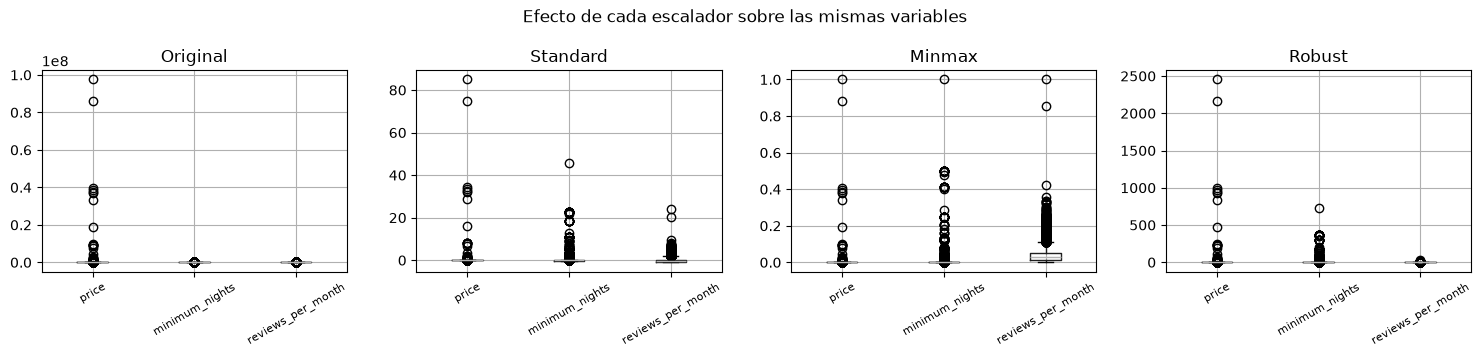

In [28]:
fig, ejes = plt.subplots(1, 4, figsize=(15, 3.6))   # cuatro paneles en una fila

# zip recorre en paralelo los paneles y los resultados: cada uno va al suyo
for eje, (nombre, valores) in zip(ejes, resultados.items()):
    valores.boxplot(ax=eje)
    eje.set_title(nombre.capitalize())
    # Los nombres de variable son largos: rotarlos evita que se solapen
    eje.tick_params(axis="x", rotation=30, labelsize=8)

plt.suptitle("Efecto de cada escalador sobre las mismas variables")
plt.tight_layout()
plt.show()

In [29]:
def verificar_escalamiento(valores, metodo, tol=1e-9):
    """Comprueba que el escalamiento produjo lo que el método promete.

    Cada escalador garantiza una propiedad distinta, así que la verificación
    también debe serlo: comprobar siempre lo mismo no valida nada.
    """
    if metodo == "standard":
        # np.allclose compara con tolerancia; exigir igualdad exacta entre
        # decimales fallaría por diferencias del orden de 1e-17.
        assert np.allclose(valores.mean(), 0, atol=tol), "media distinta de 0"
        # ddof=0 pide la desviación POBLACIONAL, que es la que usa StandardScaler;
        # pandas usa ddof=1 por defecto y no daría exactamente 1.
        assert np.allclose(valores.std(ddof=0), 1, atol=tol), "desviación distinta de 1"
        return "media ≈ 0 y desviación ≈ 1"
    if metodo == "minmax":
        assert np.allclose(valores.min(), 0, atol=tol), "mínimo distinto de 0"
        assert np.allclose(valores.max(), 1, atol=tol), "máximo distinto de 1"
        return "todos los valores en el rango [0, 1]"
    if metodo == "robust":
        assert np.allclose(valores.median(), 0, atol=1e-8), "mediana distinta de 0"
        ric = valores.quantile(0.75) - valores.quantile(0.25)
        assert np.allclose(ric, 1, atol=1e-8), "rango intercuartílico distinto de 1"
        return "mediana ≈ 0 y rango intercuartílico ≈ 1"
    raise ValueError(f"Método desconocido: {metodo}")


for metodo in ["standard", "minmax", "robust"]:
    print(f"[OK] {metodo:<9} {verificar_escalamiento(resultados[metodo]['price'], metodo)}")

[OK] standard  media ≈ 0 y desviación ≈ 1
[OK] minmax    todos los valores en el rango [0, 1]
[OK] robust    mediana ≈ 0 y rango intercuartílico ≈ 1


**Decisión de escalamiento.** Se eligió `RobustScaler`. En `price`, la mediana es $55.106
y el máximo $97.573.964, así que la media ($105.912) queda arrastrada por valores extremos.
`StandardScaler` usa media y desviación estándar, por lo que ese extremo comprime al resto
de los precios cerca de 0. `MinMaxScaler` es aún más sensible: deja casi todos los precios
pegados en 0. `RobustScaler` usa mediana y rango intercuartílico, que casi no cambian por
un extremo. Es el mismo criterio que justificó imputar con la mediana.

> **Coherencia entre decisiones.** Si se imputó con la mediana *porque hay
> valores extremos*, la misma evidencia apunta a `RobustScaler`. Usar mediana
> para imputar y `StandardScaler` para escalar no está prohibido, pero exige
> explicar por qué el mismo hecho lleva a criterios distintos. Eso separa un
> pipeline pensado de una sucesión de pasos.

## 6. Validación técnica y verificación del código

Verificar significa demostrar, con evidencia, que el resultado es correcto. La función
`validar_dataset` ejecuta varias comprobaciones y usa `assert`: si una condición no se
cumple, el notebook se detiene con un error, dejando constancia de la falla.

Comprobamos:
1. **Integridad** — que no queden valores nulos.
2. **Consistencia** — que todas las columnas sean numéricas (no quedó texto sin codificar).
3. **Coherencia** — que cada grupo one-hot sume exactamente 1 por fila: cada ***alojamiento***
   pertenece a **una sola** categoría dentro de cada variable.
4. **Duplicados** — cuántas filas repetidas hay.
5. **Dimensiones** — la forma final de la tabla.

In [30]:
def validar_dataset(df, grupos_one_hot=None):
    """
    Comprueba integridad, consistencia y coherencia del dataset final.
    Lanza AssertionError si alguna comprobacion falla.
    """
    print("VALIDACION DEL DATASET FINAL")
    print("-" * 45)

    # 1. Integridad: sin valores nulos
    nulos = int(df.isnull().sum().sum())
    assert nulos == 0, f"Quedan {nulos} valores nulos."
    print(f"[OK] Sin valores nulos (total = {nulos})")

    # 2. Consistencia: todas las columnas son numericas
    no_numericas = df.select_dtypes(exclude=[np.number]).columns.tolist()
    assert not no_numericas, f"Columnas no numericas: {no_numericas}"
    print("[OK] Todas las columnas son numericas")

    # 3. Coherencia: cada grupo one-hot suma 1 por fila (una sola categoria activa)
    if grupos_one_hot:
        for nombre, cols in grupos_one_hot.items():
            suma = df[cols].sum(axis=1)
            assert (suma == 1).all(), f"El grupo '{nombre}' no suma 1 en todas las filas."
            print(f"[OK] Grupo one-hot '{nombre}' coherente")

    # 4. Duplicados
    dup = int(df.duplicated().sum())
    print(f"[INFO] Filas duplicadas: {dup}")

    # 5. Dimensiones finales
    print(f"[INFO] Dimensiones finales: {df.shape}")
    return True


grupos = {
    "room_type": [c for c in df.columns if c.startswith("room_")],
    "host_is_superhost": [c for c in df.columns if c.startswith("superhost_")],
    "neighbourhood_cleansed": [c for c in df.columns if c.startswith("comuna_")],
}
validar_dataset(df, grupos)

VALIDACION DEL DATASET FINAL
---------------------------------------------
[OK] Sin valores nulos (total = 0)
[OK] Todas las columnas son numericas
[OK] Grupo one-hot 'room_type' coherente
[OK] Grupo one-hot 'host_is_superhost' coherente
[OK] Grupo one-hot 'neighbourhood_cleansed' coherente
[INFO] Filas duplicadas: 53
[INFO] Dimensiones finales: (18904, 48)


True

***Se dejan filas duplicadas: 52***, porque en Airbnb existen publicaciones con caracteristicas parecidas.

### Pruebas de las funciones (casos normal, límite y excepciones)

Además de validar el *dataset*, probamos la función de codificación en tres escenarios,
tal como pide la rúbrica:
- **Caso normal:** una columna pequeña y conocida; verificamos que produzca el número
  correcto de columnas y que cada fila tenga una sola categoría activa.
- **Excepción 1:** se pasa una cantidad equivocada de nombres → debe lanzar `ValueError`.
- **Excepción 2:** se pide codificar una columna inexistente → debe lanzar `KeyError`.

In [31]:
# --- Caso normal ---
prueba = pd.DataFrame({'color': ['rojo', 'azul', 'rojo', 'verde']})
res = codificar_one_hot(prueba, 'color', ['azul', 'rojo', 'verde'])
assert res.shape == (4, 3), "Numero de columnas inesperado."
assert (res.sum(axis=1) == 1).all(), "Cada fila debe tener una sola categoria activa."
print("[OK] Caso normal: codificacion correcta")

# --- Excepcion 1: numero de nombres incorrecto ---
try:
    codificar_one_hot(prueba, 'color', ['azul', 'rojo'])
except ValueError as e:
    print(f"[OK] Excepcion capturada (nombres): {e}")

# --- Excepcion 2: columna inexistente ---
try:
    codificar_one_hot(prueba, 'inexistente', ['x'])
except KeyError as e:
    print(f"[OK] Excepcion capturada (columna): {e}")

[OK] Caso normal: codificacion correcta
[OK] Excepcion capturada (nombres): Se esperaban 3 nombres para 'color' (['azul', 'rojo', 'verde']), pero se recibieron 2.
[OK] Excepcion capturada (columna): "La columna 'inexistente' no existe en el DataFrame."


In [32]:
# --- Caso límite: una sola categoría ---
prueba_limite = pd.DataFrame({'color': ['rojo', 'rojo', 'rojo']})
res = codificar_one_hot(prueba_limite, 'color', ['rojo'])
assert res.shape == (3, 1), "Con una sola categoría debe quedar una sola columna."
print("[OK] Caso límite: una sola categoría produce una sola columna")

[OK] Caso límite: una sola categoría produce una sola columna


### Visualización de control

El *boxplot* de las variables escaladas con `RobustScaler` confirma que quedaron centradas
en torno a 0. El eje vertical se recortó porque quedan valores extremos, sobre todo en
`price`, que motivaron usar la mediana al imputar y `RobustScaler` al escalar.

**Hallazgo durante la validación.** Al graficar las variables escaladas, `maximum_nights`
mostraba un valor extremo que aplastaba el resto del gráfico. El diagnóstico original
mostró un máximo de 2.147.483.647 (el mayor entero de 32 bits, es decir, un valor por
defecto del sistema) y solo 2 filas sobre 1125 noches, que es el tope habitual de la
plataforma. Se volvió a la sección 3 y se acotaron esos valores a 1125 con `clip`.
Las dos celdas siguientes se ejecutaron **después** de la corrección y verifican que
el máximo ahora es 1125 y que no quedan filas sobre ese límite.

In [33]:
df_antes["maximum_nights"].describe()

count    18904.000000
mean       582.591039
std        405.892243
min          1.000000
25%        365.000000
50%        365.000000
75%       1125.000000
max       1125.000000
Name: maximum_nights, dtype: float64

In [34]:
print(df_antes["maximum_nights"].quantile([0.5, 0.9, 0.99, 0.999, 1]))
print("Filas con más de 1125 noches:", (df_antes["maximum_nights"] > 1125).sum())

0.500     365.0
0.900    1125.0
0.990    1125.0
0.999    1125.0
1.000    1125.0
Name: maximum_nights, dtype: float64
Filas con más de 1125 noches: 0


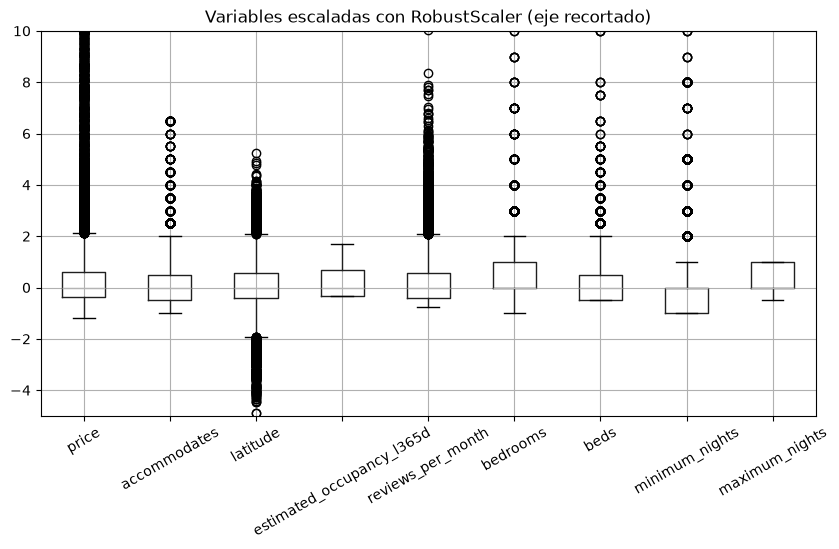

In [35]:
# El boxplot muestra mediana, cuartiles y atípicos: tras estandarizar, las tres
# cajas deben quedar centradas en torno a 0 y con anchos comparables.
df[columnas_a_escalar].boxplot(figsize=(10, 5))
plt.ylim(-5, 10)                  # recorta el eje para ver las cajas; los extremos quedan fuera del gráfico
plt.xticks(rotation=30)           # rota los nombres para que no se pisen
plt.title("Variables escaladas con RobustScaler (eje recortado)")
plt.show()

Vista final del *dataset* completamente preprocesado:

In [36]:
# Vista final: las columnas de texto desaparecieron y en su lugar hay columnas
# binarias; las numéricas quedaron escaladas con RobustScaler
print("Dataset final:", df.shape)
df.head()

Dataset final: (18904, 48)


,price,accommodates,latitude,estimated_occupancy_l365d,reviews_per_month,bedrooms,beds,minimum_nights,maximum_nights,bedrooms_imputado,...,comuna_Quilicura,comuna_Quinta_Normal,comuna_Recoleta,comuna_Renca,comuna_San_Joaquín,comuna_San_Miguel,comuna_San_Ramón,comuna_Santiago,comuna_Vitacura,comuna_Ñuñoa
0,0.105596,-1.0,0.238382,-0.333333,0.000000,0.0,-0.5,1.0,0.480263,0,...,0,0,0,0,0,0,0,0,0,0
1,0.984703,0.5,0.347902,-0.333333,-0.659794,0.0,-0.5,-1.0,1.000000,0,...,0,0,0,0,0,0,0,0,0,0
2,0.000000,-0.5,-2.738993,-0.333333,0.000000,0.0,-0.5,0.0,0.480263,0,...,0,0,0,0,0,0,0,0,0,0
3,0.609659,-0.5,0.629625,0.142857,-0.072165,0.0,-0.5,0.0,1.000000,0,...,0,0,0,0,0,0,0,0,0,0
4,0.657777,-0.5,0.461556,-0.333333,-0.567010,0.0,-0.5,2.0,0.000000,0,...,0,0,0,0,0,0,0,0,0,0


## Conclusiones y trazabilidad

El *pipeline* dejó el *dataset* con 18.904 filas y 48 columnas, sin valores nulos y con todas
las variables en formato numérico: las variables numéricas quedaron escaladas con
`RobustScaler` y las categóricas nominales, codificadas con One-Hot. Entre las decisiones
tomadas, los faltantes se imputaron con la mediana, y los valores imposibles de
`maximum_nights` (máximo de 2.147.483.647, un valor por defecto del sistema) se acotaron a 1125.
Cada paso se implementó como una función documentada y reutilizable (`cargar_datos`,
`explorar_dataframe`, `imputar_nulos_numericos`, `codificar_one_hot`, `escalar_caracteristicas`,
`validar_dataset`), garantizando un flujo modular, reproducible y verificable.

---

## 7. Recursividad: aplanar los metadatos del proyecto

Todo el procesamiento anterior fue **estructurado**: secuencias, condicionales y
bucles. Esta sección introduce la **recursividad**, que es la herramienta natural
cuando la estructura tiene profundidad desconocida. El indicador ID 2.1 la
contempla explícitamente.

El caso es real y no decorativo: los metadatos del proyecto forman un diccionario
anidado y, para exportarlos como tabla, hay que convertirlos en pares
clave-valor. Un bucle no sirve porque no se sabe cuántos niveles hay.

**Anatomía de la función recursiva:**
- *Caso base*: el valor no es un diccionario → se devuelve el par clave-valor.
- *Caso recursivo*: el valor es un diccionario → la función se llama a sí misma
  un nivel más abajo, arrastrando el prefijo de la ruta.

In [37]:
# Los metadatos del proyecto, con la estructura anidada que corresponde
METADATOS = {
    "proyecto": {
        "nombre": "Caracterización de alojamientos Airbnb en Santiago de Chile",
        "fase": "F2",
        "semilla": 42,
    },
    "datos": {
        "archivo": "datasetairbnb.csv",
        "fuente": {
            "plataforma": "Inside Airbnb",
            "autor": "Inside Airbnb (Murray Cox)",
            "url": "http://insideairbnb.com/get-the-data/",
        },
    },
    "decisiones": {
        "imputacion": {
            "estrategia": "mediana",
            "columnas": columnas_imputar,
        },
        "limpieza": {"maximum_nights": "acotado a 1125 con clip"},
        "escalador": "robust",
        "columnas_escaladas": columnas_a_escalar,
        "categoricas": ["room_type", "host_is_superhost", "neighbourhood_cleansed"],
    },
}

def aplanar(estructura, prefijo="", separador="."):
    """Aplana un diccionario anidado en uno de un solo nivel.

    Ejemplo
    -------
    >>> aplanar({"a": {"b": 1, "c": {"d": 2}}})
    {'a.b': 1, 'a.c.d': 2}
    """
    plano = {}
    for clave, valor in estructura.items():
        # Se construye la ruta completa: en el primer nivel no hay prefijo
        ruta = f"{prefijo}{separador}{clave}" if prefijo else str(clave)

        if isinstance(valor, dict):
            # CASO RECURSIVO: la función se llama a sí misma un nivel más abajo
            plano.update(aplanar(valor, ruta, separador))
        elif isinstance(valor, (list, tuple)):
            # Las secuencias se convierten en texto legible para la tabla
            plano[ruta] = ", ".join(str(v) for v in valor)
        else:
            # CASO BASE: el valor es simple, se devuelve el par
            plano[ruta] = valor
    return plano


metadatos_planos = aplanar(METADATOS)
print(f"El diccionario anidado se aplanó en {len(metadatos_planos)} pares.\n")
for clave, valor in metadatos_planos.items():
    print(f"  {clave:<28} {str(valor)[:52]}")

El diccionario anidado se aplanó en 13 pares.

  proyecto.nombre              Caracterización de alojamientos Airbnb en Santiago d
  proyecto.fase                F2
  proyecto.semilla             42
  datos.archivo                datasetairbnb.csv
  datos.fuente.plataforma      Inside Airbnb
  datos.fuente.autor           Inside Airbnb (Murray Cox)
  datos.fuente.url             http://insideairbnb.com/get-the-data/
  decisiones.imputacion.estrategia mediana
  decisiones.imputacion.columnas price, accommodates, latitude, estimated_occupancy_l
  decisiones.limpieza.maximum_nights acotado a 1125 con clip
  decisiones.escalador         robust
  decisiones.columnas_escaladas price, accommodates, latitude, estimated_occupancy_l
  decisiones.categoricas       room_type, host_is_superhost, neighbourhood_cleansed


In [38]:
# Verificación de la función recursiva: casos normal, profundo y límite
assert aplanar({"a": 1}) == {"a": 1}, "Caso plano"
assert aplanar({"a": {"b": 1}}) == {"a.b": 1}, "Un nivel de anidamiento"
assert aplanar({"a": {"b": {"c": {"d": 4}}}}) == {"a.b.c.d": 4}, "Anidamiento profundo"
assert aplanar({}) == {}, "Caso límite: diccionario vacío"
assert aplanar({"x": [1, 2, 3]}) == {"x": "1, 2, 3"}, "Listas convertidas a texto"
print("[OK] La función recursiva pasa las cinco pruebas.")

[OK] La función recursiva pasa las cinco pruebas.


> **Cuándo NO usar recursividad.** Si la profundidad se conoce y es fija, un
> bucle anidado es más claro y más rápido. La recursividad se justifica cuando la
> profundidad es variable, como aquí. Python además limita la profundidad a unos
> mil niveles, así que no reemplaza a un bucle sobre miles de filas.

---

## 8. Persistencia y trazabilidad

El resultado debe quedar guardado y documentado. Esta sección produce los
artefactos que se versionan en el repositorio y se citan en el informe.

In [39]:
ARCHIVO_PROCESADO = DIR_PROCESADO / "airbnb_procesado.csv"

# index=False evita agregar una columna con el número de fila, que no es un dato
df.to_csv(ARCHIVO_PROCESADO, index=False)

# Verificación de ida y vuelta: se relee lo guardado y se comprueba que coincide.
# Si el archivo se escribió mal, es preferible descubrirlo ahora.
releido = pd.read_csv(ARCHIVO_PROCESADO)
assert releido.shape == df.shape, "El archivo releído no coincide en dimensiones"
print(f"Guardado y verificado: {ARCHIVO_PROCESADO}")
print(f"Tamaño en disco: {ARCHIVO_PROCESADO.stat().st_size / 1024:.1f} kB")

# Los metadatos aplanados con la función recursiva de la sección 7
pd.DataFrame(list(metadatos_planos.items()), columns=["clave", "valor"]).to_csv(
    DIR_DOCS / "metadatos_proyecto.csv", index=False)
print(f"Metadatos exportados a {DIR_DOCS}/metadatos_proyecto.csv")

Guardado y verificado: c:\Users\goku9\Desktop\grupo_8_magister_mcdi500\data\processed\airbnb_procesado.csv
Tamaño en disco: 3302.9 kB
Metadatos exportados a c:\Users\goku9\Desktop\grupo_8_magister_mcdi500\docs/metadatos_proyecto.csv


In [40]:
# Resumen comparativo entre el punto de partida y el resultado.
# Esta tabla responde de una vez a la pregunta "qué cambió".
resumen = pd.DataFrame([
    {"indicador": "Filas", "inicial": df_crudo.shape[0], "final": df.shape[0]},
    {"indicador": "Columnas", "inicial": df_crudo.shape[1], "final": df.shape[1]},
    {"indicador": "Valores nulos",
     "inicial": int(df_crudo.isna().sum().sum()), "final": int(df.isna().sum().sum())},
    {"indicador": "Columnas de texto",
     "inicial": int((df_crudo.dtypes == "object").sum()),
     "final": int((df.dtypes == "object").sum())},
    {"indicador": "Filas duplicadas",
     "inicial": int(df_crudo.duplicated().sum()), "final": int(df.duplicated().sum())},
])
resumen

,indicador,inicial,final
0,Filas,18904,18904
1,Columnas,90,48
2,Valores nulos,351860,0
3,Columnas de texto,0,0
4,Filas duplicadas,0,53


---

## 9. Reflexión técnica

### Hallazgos

- **Asimetría y valores extremos en `price`.** La mediana es $55.106, el promedio $105.912 y
  el máximo $97.573.964, de modo que la media queda arrastrada por unos pocos anuncios
  extremos. Ese hecho, y no una preferencia, justificó imputar con la mediana y escalar con
  `RobustScaler`: `StandardScaler` comprimía casi todos los precios cerca de 0 y `MinMaxScaler`
  los dejaba pegados en 0.

- **Valor imposible en `maximum_nights`.** El máximo del archivo es 2.147.483.647, el mayor
  número entero que cabe en 32 bits, es decir, un valor por defecto del sistema y no un dato
  ingresado por un anfitrión. Entre el percentil 90 y el 99,9 el valor es siempre 1125, que
  corresponde al tope habitual de la plataforma. Solo 2 de 18.904 filas lo superaban, por lo
  que se acotaron a 1125 con `clip` en lugar de eliminarlas, conservando el resto de sus datos.
  El problema se detectó recién en la validación visual (sección 6), al ver que ese valor
  aplastaba el gráfico, y obligó a volver a la sección 3.

- **Filas duplicadas.** Tras eliminar `id` aparecen 52 filas idénticas. Son anuncios
  distintos con las mismas características, por lo que se conservaron.

### Dificultades y cómo se resolvieron

- **`price` venía como texto.** El precio se publica con el símbolo `$` y separadores de
  miles, por lo que pandas lo cargó como texto y falló la detección de atípicos. Se limpió
  el texto y se convirtió a número con `pd.to_numeric`.

- **El escalamiento se aplicó dos veces.** Al ejecutar varias veces la celda de escalamiento,
  la copia `df_antes` ya estaba escalada y los datos "originales" mostraban media 0 y
  desviación 1. Se resolvió reiniciando el kernel y ejecutando las celdas en orden, una sola vez.

- **La codificación depende del orden alfabético interno.** La función `codificar_one_hot`
  exige escribir los nombres en ese orden; la sección 4 mostró la alternativa con
  `get_feature_names_out`, que los genera sola.

### Decisiones que quedan abiertas

- Si los precios extremos (máximo de $97.573.964 frente a una mediana de $55.106) deben
  acotarse o eliminarse. En esta fase se conservaron y se usó `RobustScaler` para que no
  distorsionen el escalamiento.
- Si las 52 filas duplicadas deben eliminarse. Se conservaron porque cada una corresponde a un
  anuncio distinto (el `id` era único) con características idénticas.
- Si `room_type` conviene tratarla como ordinal en lugar de nominal, ya que tiene un orden de
  privacidad (habitación compartida < privada < hotel < alojamiento completo).
- Si `latitude` aporta información por sí sola, ya que se excluyó `longitude` y la ubicación
  ya está codificada en las columnas de comuna.
- Si la partición entre entrenamiento y prueba obligará a rehacer la imputación y el
  escalamiento dentro de un `Pipeline` de scikit-learn, para evitar fuga de datos.

> **Declarar lo que queda abierto evidencia más dominio que presentar todo
> resuelto.** En esta fase no debería estarlo.

---

## 10. Verificación antes de entregar

**Notebook**

- Corre completo tras *Kernel → Restart Kernel and Run All Cells*, sin errores.
- La numeración de ejecución es continua.
- Cada bloque de código está precedido por una celda narrativa que explica su lógica.
- Todas las rutas son relativas y la semilla está declarada.

**Contenido técnico**

- La procedencia del conjunto está documentada, con enlace y cita en APA 7.
- El diccionario de variables declara el rol analítico de cada una.
- Las decisiones de imputación y escalamiento están **comparadas y justificadas con cifras**.
- Hay pruebas de casos normales, límite y excepciones.

**Archivos**

- `data/raw/` conserva el archivo original sin modificar.
- `data/processed/` contiene el conjunto procesado.
- `docs/` contiene el diccionario de variables y los metadatos.

**Repositorio**

- Carpeta F2 con este notebook, commits de todos los integrantes y README actualizado.

---

*Cuaderno de la Fase 2 · MCDI500 · Magíster en Ciencia de Datos e Inteligencia
Artificial · Universidad Andrés Bello*